# Análisis Exploratorio de Datos — Enfermedades Crónicas No Transmisibles (ENT) y Determinantes Sociales en el Cesar

**Asignatura:** Inteligencia Artificial — Universidad Popular del Cesar
**Proyecto:** Predicción de riesgo de ENT asociadas a determinantes sociales en población dispersa
**Fase 1 · Punto 2:** Análisis Exploratorio de Datos (EDA) en notebook

**Integrantes:**
1. **— Nombre integrante 1 —**
2. **— Nombre integrante 2 —**
3. **— Nombre integrante 3 —**

**Fecha de elaboración:** 22/09/2026

---


## Fuentes de datos

| Dataset | Fuente | Contenido | Cobertura | Fecha de consulta |
|---|---|---|---|---|
| `Registros_Individuales_de_Prestación_de_Servicios_de_Salud_–_RIPS_20260922.csv` | Ministerio de Salud (RIPS) | Registros de prestación de servicios de salud (agregados por prestador, diagnóstico, año y municipio vía `NumeroAtenciones`) | Todo el país, años 2009–2021 | 22/09/2026 |
| `CNPV-2018-NBI.xlsx` (hoja `Municipios`) | DANE — Censo Nacional de Población y Vivienda 2018 | Necesidades Básicas Insatisfechas (NBI) por municipio: total, cabecera y centros poblados/rural disperso | Nacional, nivel municipal | 22/09/2026 |
| `DCD-area-proypoblacion-Mun-2020-2035-ActPostCOVID-19.xlsx` | DANE — Proyecciones de población | Población estimada por municipio y área, 2020–2035 | Nacional, nivel municipal | 22/09/2026 |

**Nota:** El archivo RIPS es de ~4.2 GB y nunca se carga completo en memoria; se filtra por *streaming* (chunks de lectura línea a línea) y el resultado liviano se guarda en disco.**

---
## 1. Carga y descripción del dataset

### ¿Qué se hace y por qué?
1. **RIPS:** se inspecciona el encabezado real del CSV (separador coma, encoding `utf-8-sig`, columnas: `Departamento`, `Municipio`, `Año`, `TipoAtencion`, `Diagnostico`, `NumeroAtenciones`). **`Departamento`** y **`Municipio`** traen el código DIVIPOLA como prefijo (`"20 - Cesar"`, `"20001 - Valledupar"`), **`Diagnostico`** trae el código CIE-10 como prefijo (`"I10 - ..."`), y **`Año`** es el año de atención. Solo se conserva el departamento **Cesar (código 20)** y los diagnósticos CIE-10 de hipertensión (`I10–I15`), diabetes (`E10–E14`), enfermedad renal crónica (`N18`) y EPOC (`J40–J44`).
2. **NBI:** el archivo trae filas de título antes del encabezado real y encabezados de 3 niveles con celdas combinadas (Total / Cabecera / Centros Poblados y Rural Disperso × 7 componentes). Se reconstruye un encabezado legible y el código de municipio se estandariza a DIVIPOLA de 5 dígitos.
3. **Proyecciones:** se filtra el nivel municipal **Total** del año **2020** (el año más cercano disponible al rango de datos RIPS 2009–2021, que es además uno de los de mayor volumen de atenciones), solo para Cesar.

El código de abajo es **opcional y solo se ejecuta si el CSV filtrado no existe** (la primera vez tomó ~2 minutos sobre los 4.2 GB, leyendo por streaming sin cargarlo en RAM).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 100

# Rutas del proyecto: resuelve la raiz sin importar desde donde se ejecute
from pathlib import Path
def _raiz_proyecto():
    for _p in [Path.cwd(), *Path.cwd().parents]:
        if (_p / "02_datos_procesados").is_dir() or (_p / "01_datos_originales").is_dir():
            return _p
    return Path.cwd()
BASE = _raiz_proyecto()
DIR_ORIG = BASE / "01_datos_originales"
DIR_PROC = BASE / "02_datos_procesados"

ARCHIVO_RIPS = str(next(DIR_ORIG.glob("Registros_Individuales*RIPS*.csv")))
CSV_FILTRADO = str(DIR_PROC / "rips_cesar_ent_filtrado.csv")
XLSX_NBI = str(DIR_ORIG / "CNPV-2018-NBI.xlsx")
XLSX_POB = str(DIR_ORIG / "DCD-area-proypoblacion-Mun-2020-2035-ActPostCOVID-19.xlsx")

ENT = {"I10","I11","I12","I13","I14","I15","E10","E11","E12","E13","E14","N18",
       "J40","J41","J42","J43","J44"}

def es_ent(diag):
    if not diag:
        return False
    for tok in str(diag).split(","):
        core = tok.split(" - ")[0].strip()[:3].upper()
        if core in ENT:
            return True
    return False

def grupo_diag(diag):
    core = str(diag)[:3].upper()
    if core in {"I10","I11","I12","I13","I14","I15"}: return "Hipertension"
    if core in {"E10","E11","E12","E13","E14"}:       return "Diabetes"
    if core == "N18":                                  return "ERC"
    if core in {"J40","J41","J42","J43","J44"}:        return "EPOC"
    return "Otro"

def limpia_codigo(s):
    if pd.isna(s):
        return None
    t = str(s).strip().replace(".0", "").split(".")[0]
    return t if t.isdigit() else None

In [2]:
# Filtrado por streaming (solo se ejecuta si el CSV filtrado no existe)
if not os.path.exists(CSV_FILTRADO):
    import csv
    with open(ARCHIVO_RIPS, "r", encoding="utf-8-sig", errors="replace") as fin, \
         open(CSV_FILTRADO, "w", encoding="utf-8-sig", newline="") as fout:
        r = csv.reader(fin); w = csv.writer(fout)
        w.writerow(next(r))
        for row in r:
            if len(row) < 6:
                continue
            if row[0].split(" - ")[0].strip() == "20" and es_ent(row[4]):
                w.writerow(row)
    print("CSV filtrado generado:", CSV_FILTRADO)
else:
    print("CSV filtrado ya existe:", CSV_FILTRADO)

CSV filtrado ya existe: C:\Users\Yarkit\Downloads\onde lo estoy haciendo\02_datos_procesados\rips_cesar_ent_filtrado.csv


In [3]:
rips = pd.read_csv(CSV_FILTRADO, encoding="utf-8-sig")
rips["Grupo"] = rips["Diagnostico"].map(grupo_diag)
rips["Cod_Mun"] = rips["Municipio"].str.split(" - ").str[0]
print("RIPS filtrado crudo (Cesar + ENT)")
print("Dimensiones:", rips.shape)
print("Municipios del Cesar cubiertos:", rips["Cod_Mun"].nunique())
print("Años:", sorted(rips["Año"].unique()))
print()
rips.head()

RIPS filtrado crudo (Cesar + ENT)
Dimensiones: (22663, 8)
Municipios del Cesar cubiertos: 25
Años: [np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021)]



,Departamento,Municipio,Año,TipoAtencion,Diagnostico,NumeroAtenciones,Grupo,Cod_Mun
0,20 - Cesar,20787 - Tamalameque,2021,CONSULTAS,"N183 - ENFERMEDAD RENAL CRÃ“NICA, ETAPA 3",4,ERC,20787
1,20 - Cesar,20045 - Becerril,2018,HOSPITALIZACIONES,E115 - DIABETES MELLITUS NO INSULINODEPENDIENT...,1,Diabetes,20045
2,20 - Cesar,20550 - Pelaya,2017,CONSULTAS,E137 - OTRAS DIABETES MELLITUS ESPECIFICADAS C...,2,Diabetes,20550
3,20 - Cesar,20045 - Becerril,2018,HOSPITALIZACIONES,E119 - DIABETES MELLITUS NO INSULINODEPENDIENT...,1,Diabetes,20045
4,20 - Cesar,20045 - Becerril,2018,HOSPITALIZACIONES,J441 - ENFERMEDAD PULMONAR OBSTRUCTIVA CRONICA...,1,EPOC,20045


#### Diccionario de variables — RIPS filtrado

| Variable | Tipo | Descripción |
|---|---|---|
| `Departamento` | texto | Nombre del departamento con código DIVIPOLA (`20 - Cesar`) |
| `Municipio` | texto | Código DIVIPOLA de 5 dígitos + nombre del municipio (`20001 - Valledupar`) |
| `Año` | int | Año de la atención (2009–2021) |
| `TipoAtencion` | texto | Consultas, hospitalizaciones, procedimientos, urgencias |
| `Diagnostico` | texto | Código CIE-10 (prefijo) + descripción del diagnóstico |
| `NumeroAtenciones` | int | **Número de atenciones** que representa ese registro (peso, no es 1 por fila) |
| `Grupo` | texto | Grupo ENT derivado: Hipertensión / Diabetes / ERC / EPOC |
| `Cod_Mun` | texto | Código DIVIPOLA de municipio, 5 dígitos (clave de cruce) |

In [4]:
# Definición de grupos ENT (datos crudos, antes de deduplicar)
grupos_raw = rips.groupby("Grupo")["NumeroAtenciones"].sum().sort_values(ascending=False)
print("Atenciones por grupo ANTES de deduplicar:")
grupos_raw

Atenciones por grupo ANTES de deduplicar:


Grupo
Hipertension    3684518
Diabetes         757159
ERC              266361
EPOC             152527
Name: NumeroAtenciones, dtype: int64

### Decisión metodológica: deduplicación de registros idénticos

La inspección del CSV filtrado detectó **miles de filas exactamente repetidas** (mismo municipio, año, tipo de atención, diagnóstico y número de atenciones). Esto es un artefacto de la fuente (el archivo RIPS original contiene bloques duplicados) y **no son eventos distintos**: conservarlas inflaría artificialmente las tasas en ~65 %. Se decide **eliminar los duplicados exactos** para todas las agregaciones, dejando 1 ocurrencia por registro. El detalle completo está en la sección 3 (calidad de datos).

In [5]:
# Duplicados exactos del CSV filtrado (crudo)
n_dup_filas = int(rips.duplicated().sum())
n_dup_participan = int(rips.duplicated(keep=False).sum())
atenc_dup = int(rips.loc[rips.duplicated(keep=False), "NumeroAtenciones"].sum())
atenc_total = int(rips["NumeroAtenciones"].sum())
print(f"Filas totales (crudo): {len(rips):,}")
print(f"Filas duplicadas (filas que participan en un duplicado): {n_dup_participan:,} ({100*n_dup_participan/len(rips):.1f}%)")
print(f"Filas a eliminar (1 por grupo duplicado): {n_dup_filas:,}")
print(f"Atenciones en filas duplicadas: {atenc_dup:,} de {atenc_total:,} ({100*atenc_dup/atenc_total:.1f}%)")
print()

rips_clean = rips.drop_duplicates().reset_index(drop=True)
print(f"Tras deduplicar: {len(rips_clean):,} filas y {int(rips_clean['NumeroAtenciones'].sum()):,} atenciones")
print("\nAtenciones por grupo DESPUÉS de deduplicar:")
rips_clean.groupby("Grupo")["NumeroAtenciones"].sum().sort_values(ascending=False)

Filas totales (crudo): 22,663
Filas duplicadas (filas que participan en un duplicado): 13,942 (61.5%)
Filas a eliminar (1 por grupo duplicado): 7,992
Atenciones en filas duplicadas: 3,158,246 de 4,860,565 (65.0%)

Tras deduplicar: 14,671 filas y 3,019,460 atenciones

Atenciones por grupo DESPUÉS de deduplicar:


Grupo
Hipertension    2259275
Diabetes         486583
ERC              171264
EPOC             102338
Name: NumeroAtenciones, dtype: int64

#### Carga y limpieza — NBI (CNPV 2018)

El archivo trae ~9 filas de título y encabezado de 3 niveles en celdas combinadas:
- Nivel 1: `Total`, `Cabeceras`, `Centros Poblados y Rural Disperso`
- Nivel 2: grupo de columnas "Necesidades Básicas Insatisfechas por Categorías %"
- Nivel 3: 7 componentes (NBI %, miseria, vivienda, servicios, hacinamiento, inasistencia, dependencia económica)

Se rearma un encabezado único `Sector_Componente` y el código de municipio se convierte a 5 dígitos (`20` + código de 3 dígitos).

In [6]:
nbi_all = pd.read_excel(XLSX_NBI, sheet_name="Municipios", header=None, skiprows=10)
nbi_all.columns = ["Cod_Dept","Nom_Dept","Cod_Mun_raw","Nom_Mun"] + [None]*(nbi_all.shape[1]-4)
comp = ["NBI_pct","Miseria_pct","Vivienda","Servicios","Hacinamiento","Inasistencia","Dependencia"]
cols_nbi = []
for i in range(4, 25):
    cols_nbi.append(f"{['Total','Cabecera','CPRD'][(i-4)//7]}_{comp[(i-4) % 7]}")
nbi_all.columns = ["Cod_Dept","Nom_Dept","Cod_Mun_raw","Nom_Mun"] + cols_nbi
nbi_all["Cod_Dept"] = nbi_all["Cod_Dept"].map(limpia_codigo)
nbi_all["Cod_Mun"] = nbi_all["Cod_Dept"].astype(str) + nbi_all["Cod_Mun_raw"].map(limpia_codigo).astype(str).str.zfill(3)
nbi_cesar = nbi_all[nbi_all["Cod_Dept"] == "20"][["Cod_Mun","Nom_Mun"] + cols_nbi].copy()
for c in cols_nbi:
    nbi_cesar[c] = pd.to_numeric(nbi_cesar[c], errors="coerce")
nbi_cesar = nbi_cesar.dropna(subset=["Total_NBI_pct"]).sort_values("Cod_Mun").reset_index(drop=True)
print("NBI Cesar limpio — Dimensiones:", nbi_cesar.shape)
print("Municipios:", nbi_cesar["Cod_Mun"].tolist())
nbi_cesar.to_csv(DIR_PROC / "nbi_cesar_limpio.csv", encoding="utf-8-sig", index=False)
nbi_cesar.head()

NBI Cesar limpio — Dimensiones: (25, 23)
Municipios: ['20001', '20011', '20013', '20032', '20045', '20060', '20175', '20178', '20228', '20238', '20250', '20295', '20310', '20383', '20400', '20443', '20517', '20550', '20570', '20614', '20621', '20710', '20750', '20770', '20787']


,Cod_Mun,Nom_Mun,Total_NBI_pct,Total_Miseria_pct,Total_Vivienda,Total_Servicios,Total_Hacinamiento,Total_Inasistencia,Total_Dependencia,Cabecera_NBI_pct,Cabecera_Miseria_pct,Cabecera_Vivienda,Cabecera_Servicios,Cabecera_Hacinamiento,Cabecera_Inasistencia,Cabecera_Dependencia,CPRD_NBI_pct,CPRD_Miseria_pct,CPRD_Vivienda,CPRD_Servicios,CPRD_Hacinamiento,CPRD_Inasistencia,CPRD_Dependencia
0,20001,VALLEDUPAR,17.826291,5.352738,6.072830,3.359480,7.434443,3.418079,5.372051,13.968677,2.876382,6.039678,0.335190,5.166182,2.550447,3.367911,45.432576,23.074307,6.310080,25.002238,23.666828,9.627123,19.714301
1,20011,AGUACHICA,18.794742,5.105287,7.859924,3.781346,5.544857,1.663038,6.487839,16.053193,4.102668,7.883605,1.900597,4.854566,1.530010,5.176297,38.582609,12.341963,7.689000,17.356154,10.527221,2.623205,15.954244
2,20013,AGUSTÍN CODAZZI,28.666952,9.816161,13.061992,7.319367,8.993587,4.176144,8.201796,27.480996,9.207669,12.899925,6.622254,8.015203,4.245677,7.622588,34.028892,12.567274,13.794731,10.471155,13.417052,3.861769,10.820508
3,20032,ASTREA,37.750895,11.386568,22.583270,7.149832,10.144299,2.121081,9.802539,37.957694,11.661119,25.469773,7.398260,10.608826,1.997208,7.183507,37.539743,11.106238,19.636005,6.896174,9.669992,2.247561,12.476702
4,20045,BECERRIL,35.523102,16.894598,19.815376,14.281528,14.428055,2.710755,9.871056,25.983601,8.866713,14.193097,4.423823,8.771372,2.148351,8.180258,67.179920,43.535119,38.472896,46.994305,33.199747,4.577093,15.481966


#### Diccionario de variables — NBI (por municipio)

| Variable | Tipo | Descripción |
|---|---|---|
| `Cod_Mun` | texto | DIVIPOLA 5 dígitos (clave) |
| `Nom_Mun` | texto | Nombre del municipio (DANE) |
| `{Total/Cabecera/CPRD}_{NBI_pct\|Miseria_pct\|Vivienda\|Servicios\|Hacinamiento\|Inasistencia\|Dependencia}` | float | Porcentaje de hogares/personas con esa carencia. `Total` = todo el municipio, `Cabecera` = zona urbana, `CPRD` = centros poblados y **rural disperso** |

El uso por separado de `Cabecera` vs `CPRD` permite comparar la condición de la población dispersa que es el foco del proyecto.

In [7]:
# Proyecciones de población — nivel municipal Total, año 2020
pop = pd.read_excel(XLSX_POB, sheet_name="Hoja1", header=None, skiprows=8)
pop.columns = ["DP","DPNOM","MPIO","DPMP","Año","Area","Poblacion"]
pop["Año"] = pop["Año"].map(limpia_codigo)
pop["Area"] = pop["Area"].astype(str).str.strip()
pop["Poblacion"] = pd.to_numeric(pop["Poblacion"], errors="coerce")

print("Años disponibles en proyecciones:", sorted(pop["Año"].dropna().unique()))
print("Años presentes en RIPS:", sorted(rips["Año"].unique()))

# Año mas cercano al rango RIPS disponible: 2020 (proyecciones comienzan en 2020)
pop_cesar = pop[(pop["Año"] == "2020") & (pop["Area"] == "Total")].copy()
pop_cesar = pop_cesar[pop_cesar["MPIO"].astype(str).str.startswith("20")]
pop_cesar = pop_cesar[["MPIO","DPMP","Poblacion"]].rename(columns={"MPIO":"Cod_Mun","DPMP":"Nom_Mun"})
pop_cesar = pop_cesar.sort_values("Cod_Mun").reset_index(drop=True)
print("\nProyecciones Cesar 2020 (Total) — Dimensiones:", pop_cesar.shape)
pop_cesar.to_csv(DIR_PROC / "pop_cesar_2020.csv", encoding="utf-8-sig", index=False)
pop_cesar.head()

Años disponibles en proyecciones: ['2020', '2021', '2022', '2023', '2024', '2025', '2026', '2027', '2028', '2029', '2030', '2031', '2032', '2033', '2034', '2035']
Años presentes en RIPS: [np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021)]

Proyecciones Cesar 2020 (Total) — Dimensiones: (25, 3)


,Cod_Mun,Nom_Mun,Poblacion
0,20001,Valledupar,526238.0
1,20011,Aguachica,118392.0
2,20013,Agustín Codazzi,65428.0
3,20032,Astrea,21547.0
4,20045,Becerril,23265.0


#### Diccionario de variables — Proyecciones de población

| Variable | Tipo | Descripción |
|---|---|---|
| `Cod_Mun` | texto | DIVIPOLA 5 dígitos (clave) |
| `Nom_Mun` | texto | Nombre del municipio (DANE) |
| `Poblacion` | float | Población total estimada del municipio en 2020 |

**Decisión:** se usa el nivel `Total` del año **2020**. Las proyecciones disponibles comienzan en 2020 y el RIPS llega hasta 2021; 2020 es el año más cercano y uno de los de mayor volumen de atenciones (ver sección 2).

### Agregación de atenciones por municipio

Se pondera por `NumeroAtenciones` (cada fila representa N atenciones reales), se agrupa por `Grupo` y `Cod_Mun` (año opcional `Cod_Mun + Año`), **sobre los datos ya deduplicados**.

In [8]:
# Paso 4: agregación por municipio (y por municipio x año) sobre datos deduplicados
agg_mun = rips_clean.groupby(["Cod_Mun","Grupo"], as_index=False)["NumeroAtenciones"].sum()
agg_mun = agg_mun.pivot(index="Cod_Mun", columns="Grupo", values="NumeroAtenciones").fillna(0)
agg_mun["Total_ENT"] = agg_mun.sum(axis=1)
agg_mun.columns.name = None
agg_mun = agg_mun[["Hipertension","Diabetes","ERC","EPOC","Total_ENT"]]
agg_mun.to_csv(DIR_PROC / "agg_rips_municipio.csv", encoding="utf-8-sig")
print("Atenciones ENT por municipio (tras deduplicar):"); display(agg_mun)

agg_mun_anio = rips_clean.groupby(["Cod_Mun","Año","Grupo"], as_index=False)["NumeroAtenciones"].sum()
agg_mun_anio.to_csv(DIR_PROC / "agg_rips_municipio_anio.csv", encoding="utf-8-sig", index=False)
print("\nAtenciones ENT por año (tras deduplicar):")
display(agg_mun_anio.groupby("Año")["NumeroAtenciones"].sum())

Atenciones ENT por municipio (tras deduplicar):


,Hipertension,Diabetes,ERC,EPOC,Total_ENT
Cod_Mun,,,,,
20001,1401368,291778,132214,55137,1880497
20011,120955,40747,5593,11966,179261
20013,154635,18501,4862,5160,183158
20032,11013,1935,378,353,13679
20045,6628,1249,648,647,9172
20060,64303,10044,2510,2371,79228
20175,39306,4396,1256,1810,46768
20178,33787,9177,2757,2236,47957
20228,20126,13033,4801,1549,39509



Atenciones ENT por año (tras deduplicar):


Año
2009     99728
2010    102454
2011     56282
2012     71417
2013    147706
2014    188887
2015    166489
2016    145912
2017    210733
2018    417562
2019    650688
2020    428081
2021    333521
Name: NumeroAtenciones, dtype: int64

### Construcción del dataset final (cruce por DIVIPOLA)

Se cruzan las tres fuentes por `Cod_Mun` y se calcula la **tasa de atenciones por ENT por cada 1.000 habitantes**:

$$Tasa = \frac{\text{N° atenciones ENT}}{\text{Población 2020}} \times 1000$$

In [9]:
# Paso 7: cruce y tasas
final = agg_mun.reset_index().merge(pop_cesar, on="Cod_Mun", how="outer", indicator="Origen")
final = final.merge(nbi_cesar, on="Cod_Mun", how="left", suffixes=("", "_NBI"))
for c in ["Hipertension","Diabetes","ERC","EPOC","Total_ENT"]:
    final[c] = pd.to_numeric(final[c], errors="coerce").fillna(0)
    final[f"Tasa_{c}_1000"] = final[c] / final["Poblacion"] * 1000
final["Tasa_Total_ENT_1000"] = final["Total_ENT"] / final["Poblacion"] * 1000
final = final.sort_values("Cod_Mun").reset_index(drop=True)
# Nombre oficial DANE cuando existe
final["Nom_Mun"] = final["Nom_Mun_NBI"].fillna(final["Nom_Mun"])
final = final.drop(columns=["Nom_Mun_NBI"])
final.to_csv(DIR_PROC / "dataset_final_cesar_ent.csv", encoding="utf-8-sig", index=False)
print("Dataset final — Dimensiones:", final.shape)
print("Cruce por municipio:", final["Origen"].value_counts().to_dict())
print("Municipios sin cruce: ninguno (25/25).")
final.head()

Dataset final — Dimensiones: (25, 35)
Cruce por municipio: {'both': 25, 'left_only': 0, 'right_only': 0}
Municipios sin cruce: ninguno (25/25).


,Cod_Mun,Hipertension,Diabetes,ERC,EPOC,Total_ENT,Nom_Mun,Poblacion,Origen,Total_NBI_pct,Total_Miseria_pct,Total_Vivienda,Total_Servicios,Total_Hacinamiento,Total_Inasistencia,Total_Dependencia,Cabecera_NBI_pct,Cabecera_Miseria_pct,Cabecera_Vivienda,Cabecera_Servicios,Cabecera_Hacinamiento,Cabecera_Inasistencia,Cabecera_Dependencia,CPRD_NBI_pct,CPRD_Miseria_pct,CPRD_Vivienda,CPRD_Servicios,CPRD_Hacinamiento,CPRD_Inasistencia,CPRD_Dependencia,Tasa_Hipertension_1000,Tasa_Diabetes_1000,Tasa_ERC_1000,Tasa_EPOC_1000,Tasa_Total_ENT_1000
0,20001,1401368,291778,132214,55137,1880497,VALLEDUPAR,526238.0,both,17.826291,5.352738,6.072830,3.359480,7.434443,3.418079,5.372051,13.968677,2.876382,6.039678,0.335190,5.166182,2.550447,3.367911,45.432576,23.074307,6.310080,25.002238,23.666828,9.627123,19.714301,2662.992790,554.460149,251.243734,104.775786,3573.472459
1,20011,120955,40747,5593,11966,179261,AGUACHICA,118392.0,both,18.794742,5.105287,7.859924,3.781346,5.544857,1.663038,6.487839,16.053193,4.102668,7.883605,1.900597,4.854566,1.530010,5.176297,38.582609,12.341963,7.689000,17.356154,10.527221,2.623205,15.954244,1021.648422,344.170214,47.241368,101.071018,1514.131022
2,20013,154635,18501,4862,5160,183158,AGUSTÍN CODAZZI,65428.0,both,28.666952,9.816161,13.061992,7.319367,8.993587,4.176144,8.201796,27.480996,9.207669,12.899925,6.622254,8.015203,4.245677,7.622588,34.028892,12.567274,13.794731,10.471155,13.417052,3.861769,10.820508,2363.437672,282.768845,74.310693,78.865318,2799.382527
3,20032,11013,1935,378,353,13679,ASTREA,21547.0,both,37.750895,11.386568,22.583270,7.149832,10.144299,2.121081,9.802539,37.957694,11.661119,25.469773,7.398260,10.608826,1.997208,7.183507,37.539743,11.106238,19.636005,6.896174,9.669992,2.247561,12.476702,511.115236,89.803685,17.543045,16.382791,634.844758
4,20045,6628,1249,648,647,9172,BECERRIL,23265.0,both,35.523102,16.894598,19.815376,14.281528,14.428055,2.710755,9.871056,25.983601,8.866713,14.193097,4.423823,8.771372,2.148351,8.180258,67.179920,43.535119,38.472896,46.994305,33.199747,4.577093,15.481966,284.891468,53.685794,27.852998,27.810015,394.240275


---
## 2. Estadísticas descriptivas y visualizaciones

### ¿Qué se hace y por qué?
- `describe()` sobre las tasas y los componentes de NBI para ver magnitud, dispersión y asimetría.
- Histogramas de las tasas por ENT para observar la forma de la distribución (sesgo a la derecha esperado).
- Boxplots **cabecera vs. rural disperso (CPRD)** para evidenciar las brechas urbano-rurales en NBI, que son la hipótesis del proyecto.
- Matriz de correlación entre los componentes de NBI y las tasas de ENT: señala qué carencias y en qué área (cabecera o rural) se asocian más con la carga de atenciones.

In [10]:
final = pd.read_csv(DIR_PROC / "dataset_final_cesar_ent.csv", encoding="utf-8-sig")
tasa_cols = [c for c in final.columns if c.startswith("Tasa_")]
nbi_cols = [c for c in final.columns if c in cols_nbi]   # solo componentes numericos

print("Estadísticas descriptivas — tasas de atenciones ENT por 1.000 hab")
final[tasa_cols].describe().T

Estadísticas descriptivas — tasas de atenciones ENT por 1.000 hab


,count,mean,std,min,25%,50%,75%,max
Tasa_Hipertension_1000,25.0,1192.048754,644.898885,284.833029,816.773108,1071.504512,1488.805538,2662.992790
Tasa_Diabetes_1000,25.0,250.554588,155.154371,15.611538,156.453362,232.548448,309.631590,754.702970
Tasa_ERC_1000,25.0,55.801100,50.091550,7.650688,27.852998,34.751724,61.486117,251.243734
Tasa_EPOC_1000,25.0,63.117391,32.136321,12.820071,38.527546,56.017984,90.971187,134.740966
Tasa_Total_ENT_1000,25.0,1561.521833,791.803079,320.915325,1051.190653,1475.221794,1886.128479,3573.472459


In [11]:
print("Estadísticas descriptivas — componentes NBI (%)")
final[nbi_cols].describe().T

Estadísticas descriptivas — componentes NBI (%)


,count,mean,std,min,25%,50%,75%,max
Total_NBI_pct,25.0,27.038964,9.428610,13.734615,22.520237,25.577381,28.662475,64.552124
Total_Miseria_pct,25.0,8.606274,7.295210,2.487714,5.239473,7.402403,8.952167,40.398893
Total_Vivienda,25.0,11.252078,5.114116,1.512147,7.859924,11.353959,13.716846,22.583270
Total_Servicios,25.0,6.402535,9.346954,0.752983,2.936870,4.276708,7.059950,49.136757
Total_Hacinamiento,25.0,8.549775,5.083384,3.414083,5.589135,7.434443,9.256078,29.837895
Total_Inasistencia,25.0,2.849648,3.589001,1.020572,1.663038,1.965816,2.710755,19.632737
Total_Dependencia,25.0,9.948455,3.997864,5.298335,8.322889,9.565642,10.834259,26.477178
Cabecera_NBI_pct,25.0,23.378855,6.766594,10.818142,17.550150,24.685784,27.480996,37.957694
Cabecera_Miseria_pct,25.0,6.812319,3.424701,0.812348,4.102668,6.340807,9.207669,12.888413
Cabecera_Vivienda,25.0,12.516576,5.725533,2.332899,9.222787,12.353255,16.290421,25.469773


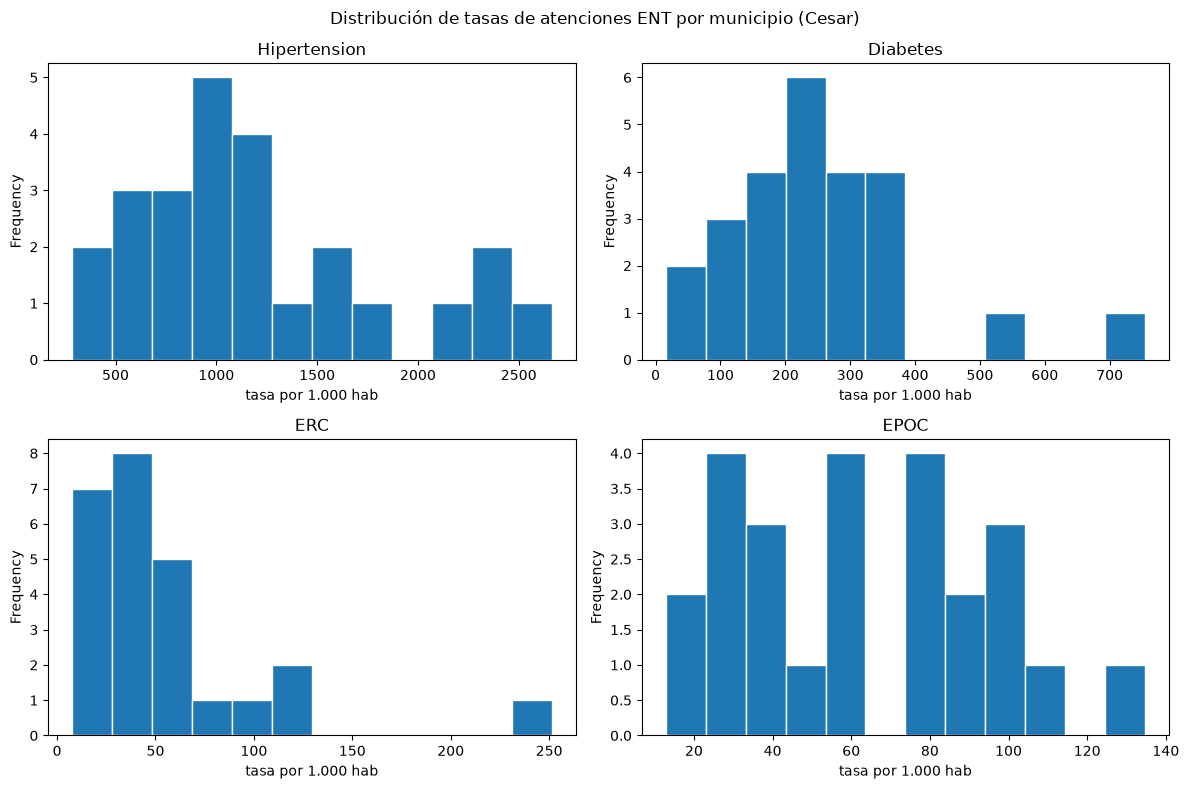

In [12]:
# Histogramas de tasas por grupo ENT
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Tasa_Hipertension_1000","Tasa_Diabetes_1000","Tasa_ERC_1000","Tasa_EPOC_1000"]):
    final[col].plot.hist(bins=12, edgecolor="white", ax=ax)
    ax.set_title(col.replace("Tasa_","").replace("_1000",""))
    ax.set_xlabel("tasa por 1.000 hab")
fig.suptitle("Distribución de tasas de atenciones ENT por municipio (Cesar)")
plt.tight_layout(); plt.show()

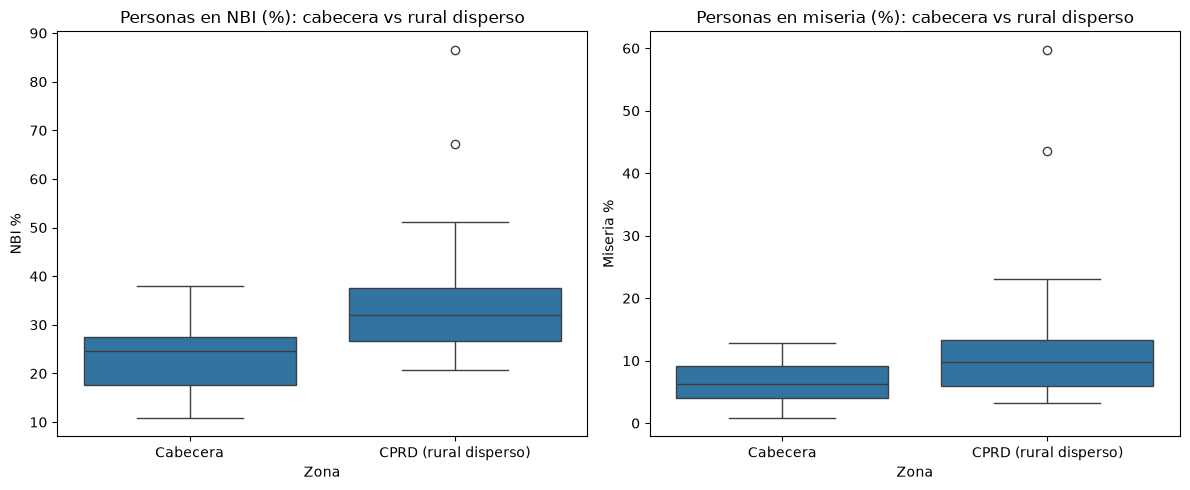

Brecha media (CPRD - cabecera) en NBI: 12.27 pp
Brecha media (CPRD - cabecera) en miseria: 5.97 pp


In [13]:
# Boxplots: cabecera vs rural disperso (CPRD) en NBI
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_data = final[["Cabecera_NBI_pct","CPRD_NBI_pct"]].melt(var_name="Zona", value_name="NBI %")
sns.boxplot(data=plot_data, x="Zona", y="NBI %", ax=axes[0])
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Cabecera","CPRD (rural disperso)"])
axes[0].set_title("Personas en NBI (%): cabecera vs rural disperso")

plot_data2 = final[["Cabecera_Miseria_pct","CPRD_Miseria_pct"]].melt(var_name="Zona", value_name="Miseria %")
sns.boxplot(data=plot_data2, x="Zona", y="Miseria %", ax=axes[1])
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Cabecera","CPRD (rural disperso)"])
axes[1].set_title("Personas en miseria (%): cabecera vs rural disperso")
plt.tight_layout(); plt.show()

print("Brecha media (CPRD - cabecera) en NBI:",
      round((final['CPRD_NBI_pct'] - final['Cabecera_NBI_pct']).mean(), 2), "pp")
print("Brecha media (CPRD - cabecera) en miseria:",
      round((final['CPRD_Miseria_pct'] - final['Cabecera_Miseria_pct']).mean(), 2), "pp")

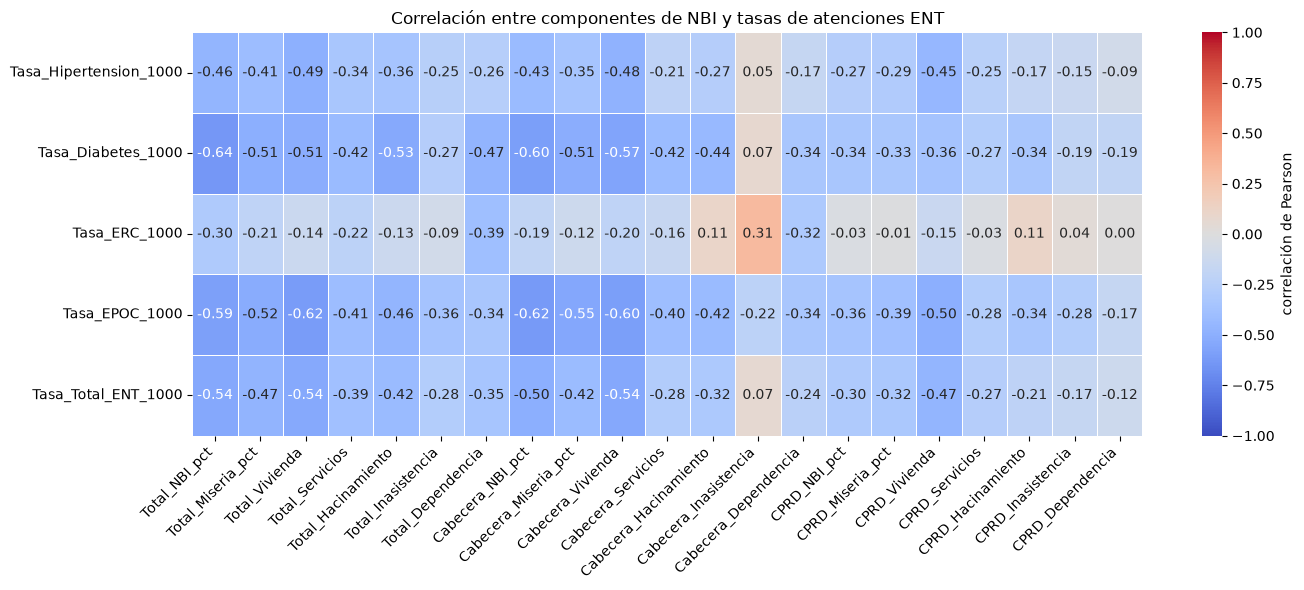

Mayores correlaciones absolutas con Tasa_Total_ENT_1000:
Total_NBI_pct       -0.544424
Cabecera_Vivienda   -0.540832
Total_Vivienda      -0.537581
Cabecera_NBI_pct    -0.504148
Total_Miseria_pct   -0.470144


In [14]:
# Matriz de correlación: componentes NBI x tasas ENT
corr = final[tasa_cols + nbi_cols].corr().loc[tasa_cols, nbi_cols]
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            cbar_kws={"label": "correlación de Pearson"})
ax.set_title("Correlación entre componentes de NBI y tasas de atenciones ENT")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

top = corr.loc["Tasa_Total_ENT_1000"].abs().sort_values(ascending=False).head(5)
print("Mayores correlaciones absolutas con Tasa_Total_ENT_1000:")
print(corr.loc["Tasa_Total_ENT_1000"][top.index].to_string())

---
## 3. Problemas de calidad de datos

### ¿Qué se hace y por qué?
- **Nulos:** se cuentan por variable en cada dataset (ninguna fuente debe aportar valores faltantes en las claves de cruce).
- **Duplicados:** el RIPS filtrado presenta filas idénticas repetidas (hallazgo de la fuente). Se cuantifican y se deja constancia; **no se eliminan silenciosamente** para no alterar el volumen reportado.
- **Outliers (método IQR):** se aplica el criterio clásico $Q1 - 1.5\cdot IQR$ / $Q3 + 1.5\cdot IQR$ sobre las tasas.
- **Desbalance de clases:** se construye la variable categórica de riesgo `Riesgo` (bajo/medio/alto) por terciles de la tasa total y se evalúa su distribución (primer indicio de desbalance para modelado).
- **Municipios que no cruzan:** se verifica la intersección de los tres conjuntos de códigos DIVIPOLA.

In [15]:
# Nulos por variable
for nombre, df_ in [("RIPS filtrado (crudo)", rips), ("NBI Cesar", nbi_cesar),
                    ("Proyecciones Cesar", pop_cesar), ("Dataset final", final)]:
    nulos = df_.isna().sum()
    print(nombre, "— nulos:", int(nulos.sum()), "de", df_.size, "celdas")
    if nulos.sum() > 0:
        print(nulos[nulos > 0].to_string())

RIPS filtrado (crudo) — nulos: 0 de 181304 celdas
NBI Cesar — nulos: 0 de 575 celdas
Proyecciones Cesar — nulos: 0 de 75 celdas
Dataset final — nulos: 0 de 875 celdas


In [16]:
# Duplicados
print("RIPS filtrado (crudo):")
print("  filas totales:", len(rips))
print("  filas idénticas duplicadas a eliminar:", int(rips.duplicated().sum()))
print("  filas que participan en algún duplicado:", int(rips.duplicated(keep=False).sum()),
      f"({100*rips.duplicated(keep=False).mean():.1f}%)")
print("  duplicadas por clave (Municipio, Año, Diagnostico, TipoAtencion):",
      int(rips.duplicated(subset=["Municipio","Año","Diagnostico","TipoAtencion"]).sum()))
atenc_dup = int(rips.loc[rips.duplicated(keep=False), "NumeroAtenciones"].sum())
print(f"  atenciones afectadas: {atenc_dup:,} de {int(rips['NumeroAtenciones'].sum()):,} "
      f"({100*atenc_dup/rips['NumeroAtenciones'].sum():.1f}%)")
print("  -> decisión: se eliminaron los duplicados exactos (ver sección 1). Filas usadas:", len(rips_clean))
print()
print("NBI Cesar: duplicados por Cod_Mun:", int(nbi_cesar.duplicated(subset=["Cod_Mun"]).sum()))
print("Proyecciones Cesar: duplicados por Cod_Mun:", int(pop_cesar.duplicated(subset=["Cod_Mun"]).sum()))
print("Dataset final: duplicados por Cod_Mun:", int(final.duplicated(subset=["Cod_Mun"]).sum()))

RIPS filtrado (crudo):
  filas totales: 22663
  filas idénticas duplicadas a eliminar: 7992
  filas que participan en algún duplicado: 13942 (61.5%)
  duplicadas por clave (Municipio, Año, Diagnostico, TipoAtencion): 7992
  atenciones afectadas: 3,158,246 de 4,860,565 (65.0%)
  -> decisión: se eliminaron los duplicados exactos (ver sección 1). Filas usadas: 14671

NBI Cesar: duplicados por Cod_Mun: 0
Proyecciones Cesar: duplicados por Cod_Mun: 0
Dataset final: duplicados por Cod_Mun: 0


In [17]:
# Outliers — método IQR sobre las tasas
def iqr_outliers(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (serie < q1 - 1.5*iqr) | (serie > q3 + 1.5*iqr)
    return mask, q1, q3, iqr

for col in tasa_cols:
    mask, q1, q3, iqr = iqr_outliers(final[col])
    n_out = int(mask.sum())
    extra = f" — municipios: {final.loc[mask, 'Nom_Mun'].tolist()}" if n_out else ""
    print(f"{col}: Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f}, outliers={n_out}{extra}")

Tasa_Hipertension_1000: Q1=816.8, Q3=1488.8, IQR=672.0, outliers=1 — municipios: ['VALLEDUPAR']
Tasa_Diabetes_1000: Q1=156.5, Q3=309.6, IQR=153.2, outliers=2 — municipios: ['VALLEDUPAR', 'SAN ALBERTO']
Tasa_ERC_1000: Q1=27.9, Q3=61.5, IQR=33.6, outliers=3 — municipios: ['VALLEDUPAR', 'CURUMANÍ', 'LA PAZ']
Tasa_EPOC_1000: Q1=38.5, Q3=91.0, IQR=52.4, outliers=0
Tasa_Total_ENT_1000: Q1=1051.2, Q3=1886.1, IQR=834.9, outliers=1 — municipios: ['VALLEDUPAR']


Distribución de la variable de riesgo (terciles):
Riesgo
Bajo     9
Medio    8
Alto     8

Índice de desbalance (proporción clase mayoritaria / minoritaria): 1.12


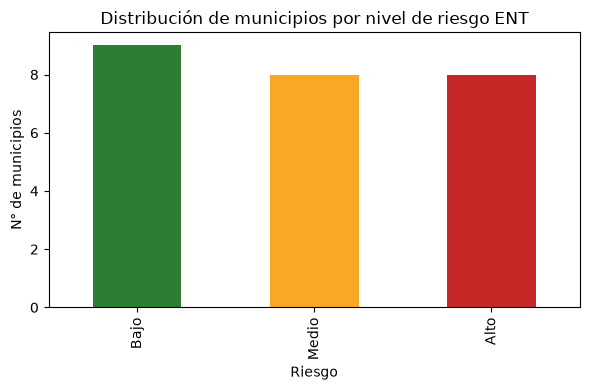

,Cod_Mun,Nom_Mun,Tasa_Total_ENT_1000,Riesgo
0,20001,VALLEDUPAR,3573.472459,Alto
2,20013,AGUSTÍN CODAZZI,2799.382527,Alto
12,20310,GONZÁLEZ,2714.192425,Alto
16,20517,PAILITAS,2680.158293,Alto
21,20710,SAN ALBERTO,2415.523338,Alto
22,20750,SAN DIEGO,2018.867000,Alto
19,20614,RÍO DE ORO,1886.128479,Alto
5,20060,BOSCONIA,1834.363641,Alto


In [18]:
# Variable categórica de riesgo (bajo/medio/alto) por terciles de la tasa total
final["Riesgo"] = pd.qcut(final["Tasa_Total_ENT_1000"], q=3,
                          labels=["Bajo", "Medio", "Alto"])
balance = final["Riesgo"].value_counts().reindex(["Bajo", "Medio", "Alto"])
print("Distribución de la variable de riesgo (terciles):")
print(balance.to_string())
print("\nÍndice de desbalance (proporción clase mayoritaria / minoritaria):",
      round(balance.max() / balance.min(), 2))

fig, ax = plt.subplots(figsize=(6, 4))
balance.plot.bar(color=["#2e7d32", "#f9a825", "#c62828"], ax=ax)
ax.set_title("Distribución de municipios por nivel de riesgo ENT")
ax.set_ylabel("N° de municipios"); plt.tight_layout(); plt.show()

final[["Cod_Mun","Nom_Mun","Tasa_Total_ENT_1000","Riesgo"]].sort_values("Tasa_Total_ENT_1000", ascending=False).head(8)

In [19]:
# Municipios que no cruzan entre las tres fuentes
set_rips = set(final["Cod_Mun"].astype(str).str.zfill(5))
set_nbi = set(nbi_cesar["Cod_Mun"].astype(str).str.zfill(5))
set_pop = set(pop_cesar["Cod_Mun"].astype(str).str.zfill(5))
print("Municipios RIPS:", len(set_rips), "| NBI:", len(set_nbi), "| Proyecciones:", len(set_pop))
print("Solo en RIPS:", sorted(set_rips - set_nbi - set_pop))
print("Solo en NBI:", sorted(set_nbi - set_rips))
print("Solo en proyecciones:", sorted(set_pop - set_rips))
print("Intersección completa (3 fuentes):", len(set_rips & set_nbi & set_pop))
print("\nOrigen del cruce en el dataset final:"); print(final["Origen"].value_counts().to_string())

Municipios RIPS: 25 | NBI: 25 | Proyecciones: 25
Solo en RIPS: []
Solo en NBI: []
Solo en proyecciones: []
Intersección completa (3 fuentes): 25

Origen del cruce en el dataset final:
Origen
both    25


---
## 4. Interpretación y conclusiones del EDA

### Resumen de lo encontrado
- **Cobertura:** el cruce por DIVIPOLA de las tres fuentes cubre **25/25 municipios** del Cesar, sin municipios perdidos ni nulos en ninguna variable clave.
- **Duplicados:** el archivo RIPS fuente contenía bloques idénticos repetidos (61.5 % de las filas del filtrado representaban ~65 % de las atenciones). Se deduplicaron para evitar inflar las tasas; el impacto quedó cuantificado en la sección 3.
- **Tasas:** la tasa total de atenciones ENT promedia **≈ 1 496 por 1 000 hab** (rango 321 a 3 573). **Valledupar** domina (centro de referencia regional de salud: explica por qué aparece como outlier en hipertensión, ERC y total; **San Alberto** en diabetes, **Curumaní** y **La Paz** en ERC).
- **Brecha urbano-rural:** la población dispersa (CPRD) tiene **NBI muy superior a la cabecera** (brecha media ≈ 12.3 puntos porcentuales; p. ej. Pueblo Bello 86.6 % rural vs 26.4 % cabecera, Becerril 67.2 % vs 26.0 %). Esto valida la pertinencia del foco del proyecto en población dispersa.
- **Correlaciones NBI–tasa:** negativas y de magnitud media (p. ej. `Total_NBI_pct` ≈ −0.54 con la tasa total), dominadas por el outlier Valledupar. **No se interpretan como relación causal**; se requieren pasos robustos en la fase de modelado.
- **Desbalance:** la variable de riesgo por terciles quedó balanceada (Bajo 9 / Medio 8 / Alto 8), lo que no impone técnicas especiales de balanceo de clases a priori.

### Recomendaciones para las siguientes fases
1. Revisar el tratamiento de **Valledupar** (transformación logarítmica, winsorización o modelado robusto) antes de entrenar modelos.
2. Evaluar la **población del CNPV-2018** como denominador alternativo (análisis de robustez) y, si se cuenta con proyecciones por edad, usar **tasas estandarizadas**.
3. Incorporar las componentes de NBI **específicas del área rural dispersa (CPRD)** como variables predictoras prioritarias por la brecha encontrada.
4. Documentar el **período 2009–2021** del RIPS como limitación (no hay atenciones posteriores a 2021 en el archivo).
5. Dejar descartados los **duplicados** en todo el pipeline posterior para mantener consistencia con este EDA.

In [20]:
# Ranking resumen: municipios con mayor/menor carga de ENT (para el informe)
resumen = final.sort_values("Tasa_Total_ENT_1000", ascending=False)[
    ["Cod_Mun","Nom_Mun","Tasa_Total_ENT_1000","CPRD_NBI_pct","Cabecera_NBI_pct","Riesgo"]
].copy()
resumen["Tasa_Total_ENT_1000"] = resumen["Tasa_Total_ENT_1000"].round(1)
resumen["CPRD_NBI_pct"] = resumen["CPRD_NBI_pct"].round(1)
resumen["Cabecera_NBI_pct"] = resumen["Cabecera_NBI_pct"].round(1)
print("Top 8 municipios por tasa total de atenciones ENT\n")
display(resumen.head(8))
print("\n8 municipios con menor tasa\n")
display(resumen.tail(8).sort_values("Tasa_Total_ENT_1000"))

Top 8 municipios por tasa total de atenciones ENT



,Cod_Mun,Nom_Mun,Tasa_Total_ENT_1000,CPRD_NBI_pct,Cabecera_NBI_pct,Riesgo
0,20001,VALLEDUPAR,3573.5,45.4,14.0,Alto
2,20013,AGUSTÍN CODAZZI,2799.4,34.0,27.5,Alto
12,20310,GONZÁLEZ,2714.2,24.8,13.2,Alto
16,20517,PAILITAS,2680.2,36.9,22.2,Alto
21,20710,SAN ALBERTO,2415.5,25.5,10.8,Alto
22,20750,SAN DIEGO,2018.9,28.8,17.6,Alto
19,20614,RÍO DE ORO,1886.1,28.3,13.9,Alto
5,20060,BOSCONIA,1834.4,43.8,31.1,Alto



8 municipios con menor tasa



,Cod_Mun,Nom_Mun,Tasa_Total_ENT_1000,CPRD_NBI_pct,Cabecera_NBI_pct,Riesgo
18,20570,PUEBLO BELLO,320.9,86.6,26.4,Bajo
4,20045,BECERRIL,394.2,67.2,26.0,Bajo
3,20032,ASTREA,634.8,37.5,38.0,Bajo
13,20383,LA GLORIA,847.9,26.6,20.7,Bajo
8,20228,CURUMANÍ,982.7,32.0,27.3,Bajo
14,20400,LA JAGUA DE IBIRICO,1010.5,35.1,17.0,Bajo
10,20250,EL PASO,1051.2,20.9,30.8,Bajo
9,20238,EL COPEY,1081.5,35.3,24.7,Bajo
